# Weather Time Series Analysis
## Visualisasi Data - Midterm Project

**Dataset:** `cleaned_weather.csv` — data cuaca tahun 2020 yang direkam setiap **10 menit**
(21 kolom: 1 kolom waktu + 20 variabel meteorologi)
**Sumber data asli:** stasiun cuaca Max Planck Institute for Biogeochemistry, Jena (Jerman)
**Total observasi:** 52.696 baris (sebelum dibersihkan)
**Lokasi file:** [Folder Google Drive "Visualisasidata"](https://drive.google.com/drive/folders/170Rk4j_kMz1w5CgitNmE1n6m_QmWgU1l?usp=drive_link)

**Variabel utama:** suhu udara `T` (°C), didukung titik embun `Tdew`, suhu logger `Tlog`, dan curah hujan `rain`.

## 1. Load dan Persiapan Data

In [ ]:
import os
import sys
import glob
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display

# ---------- Gaya visual (berlaku untuk semua plot) ----------
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.axisbelow': True,          # grid di belakang data
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e',
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e1e0d9',
    'grid.linewidth': 0.8,
    'xtick.color': '#898781',
    'ytick.color': '#898781',
    'xtick.labelcolor': '#52514e',
    'ytick.labelcolor': '#52514e',
    'legend.frameon': False,
    'font.size': 11,
})

# Palet warna (sudah divalidasi aman untuk pembaca buta warna)
BIRU, ORANYE, TOSKA, KUNING = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
MERAH, UNGU = '#e34948', '#6250d6'
TINTA, TINTA_2 = '#0b0b0b', '#52514e'          # warna teks utama & sekunder

BULAN_ID = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun',
            'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']


def tgl_id(ts):
    """Format tanggal Indonesia, contoh: 8 Agu 2020."""
    return f'{ts.day} {BULAN_ID[ts.month - 1]} {ts.year}'


def format_sumbu_bulan(ax):
    """Sumbu-x bertipe tanggal -> label bulan berbahasa Indonesia."""
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: BULAN_ID[mdates.num2date(x).month - 1]))


def format_celsius(ax):
    """Tick sumbu-y berupa angka bulat (kelipatan 1/2/5/10) + satuan °C."""
    ax.yaxis.set_major_locator(MaxNLocator(steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{v:g}°C'))


print('Library & gaya visual siap.')

Library & gaya visual siap.


### 1.1 Load Dataset dari Google Drive



In [ ]:
# ============================================================
# Konfigurasi sumber data
# ============================================================
GDRIVE_FOLDER_URL = 'https://drive.google.com/drive/folders/170Rk4j_kMz1w5CgitNmE1n6m_QmWgU1l?usp=drive_link'
NAMA_FOLDER_DRIVE = 'Visualisasidata'    # nama folder di Google Drive
CSV_NAME = 'cleaned_weather.csv'         # nama file CSV di folder tsb
DATA_DIR = 'DATASET'                     # folder lokal tujuan unduhan
CSV_PATH_MANUAL = ''                     # opsional, contoh: 'D:/kuliah/cleaned_weather.csv'

IN_COLAB = 'google.colab' in sys.modules


def cari_csv(folder):
    """Cari cleaned_weather.csv (atau *weather*.csv) di dalam folder."""
    if not os.path.isdir(folder):
        return None
    hasil = glob.glob(os.path.join(folder, '**', CSV_NAME), recursive=True)
    if not hasil:
        hasil = glob.glob(os.path.join(folder, '**', '*weather*.csv'), recursive=True)
    return sorted(hasil)[0] if hasil else None


def unduh_dari_gdrive():
    try:
        import gdown
    except ImportError:
        import subprocess
        print('Menginstal gdown ...')
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=False)
        importlib.invalidate_caches()
        try:
            import gdown
        except ImportError:
            print('⚠ gdown tidak bisa diinstal.')
            return None
    print('Mengunduh dataset dari Google Drive ...')
    try:
        gdown.download_folder(url=GDRIVE_FOLDER_URL, output=DATA_DIR, quiet=False)
    except Exception as err:
        print(f'⚠ Gagal mengunduh via gdown: {err}')
    return cari_csv(DATA_DIR)


def cari_di_colab_drive():
    """Khusus Google Colab: mount Google Drive lalu cari folder NAMA_FOLDER_DRIVE."""
    from google.colab import drive
    drive.mount('/content/drive')
    for pola in ['/content/drive/MyDrive/{}',
                 '/content/drive/MyDrive/*/{}',
                 '/content/drive/MyDrive/*/*/{}']:
        for folder in glob.glob(pola.format(NAMA_FOLDER_DRIVE)):
            path = cari_csv(folder)
            if path:
                return path
    return None


if CSV_PATH_MANUAL:
    csv_path = CSV_PATH_MANUAL
elif os.path.exists(CSV_NAME):
    csv_path = CSV_NAME
else:
    csv_path = cari_csv(DATA_DIR) or unduh_dari_gdrive()
    if csv_path is None and IN_COLAB:
        csv_path = cari_di_colab_drive()

if not csv_path or not os.path.exists(csv_path):
    raise FileNotFoundError(
        'File CSV tidak ditemukan. Solusi: (1) share folder Google Drive sebagai '
        '"Anyone with the link", (2) unduh cleaned_weather.csv secara manual ke '
        f'folder {DATA_DIR}/, atau (3) isi CSV_PATH_MANUAL dengan path file CSV.')

print('Loading dataset...')
df_raw = pd.read_csv(csv_path)
df_raw['date'] = pd.to_datetime(df_raw['date'])
df_raw = df_raw.sort_values('date').reset_index(drop=True)

print(f'File          : {csv_path}')
print(f'Dataset loaded: {len(df_raw):,} rows x {df_raw.shape[1]} columns')
print(f'Date range    : {df_raw["date"].min()} to {df_raw["date"].max()}')
print(f'Columns       : {list(df_raw.columns)}')

Mengunduh dataset dari Google Drive ...


Retrieving folder contents


Processing file 1MXlEopl6xBcGagrgg4xAor_qE7rr8XyE cleaned_weather.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1MXlEopl6xBcGagrgg4xAor_qE7rr8XyE
To: /content/DATASET/cleaned_weather.csv
100%|██████████| 6.87M/6.87M [00:00<00:00, 42.1MB/s]
Download completed


Loading dataset...
File          : DATASET/cleaned_weather.csv
Dataset loaded: 52,696 rows x 21 columns
Date range    : 2020-01-01 00:10:00 to 2021-01-01 00:00:00
Columns       : ['date', 'p', 'T', 'Tpot', 'Tdew', 'rh', 'VPmax', 'VPact', 'VPdef', 'sh', 'H2OC', 'rho', 'wv', 'max. wv', 'wd', 'rain', 'raining', 'SWDR', 'PAR', 'max. PAR', 'Tlog']


### 1.2 Kamus Variabel

| Kolom | Keterangan | Satuan |
|---|---|---|
| `date` | Waktu pencatatan (interval 10 menit) | – |
| `p` | Tekanan udara | mbar |
| `T` | **Suhu udara** | °C |
| `Tpot` | Suhu potensial | K |
| `Tdew` | Suhu titik embun | °C |
| `rh` | Kelembapan relatif | % |
| `VPmax` | Tekanan uap jenuh | mbar |
| `VPact` | Tekanan uap aktual | mbar |
| `VPdef` | Defisit tekanan uap (`VPmax − VPact`) | mbar |
| `sh` | Kelembapan spesifik | g/kg |
| `H2OC` | Konsentrasi uap air | mmol/mol |
| `rho` | Densitas udara | g/m³ |
| `wv` | Kecepatan angin | m/s |
| `max. wv` | Kecepatan angin maksimum | m/s |
| `wd` | Arah angin | derajat |
| `rain` | Curah hujan | mm |
| `raining` | Lama hujan dalam interval 10 menit | detik |
| `SWDR` | Radiasi matahari gelombang pendek | W/m² |
| `PAR` | Radiasi aktif fotosintesis | µmol/m²/s |
| `max. PAR` | PAR maksimum | µmol/m²/s |
| `Tlog` | Suhu internal *data logger* (perangkat pencatat) | °C |

### 1.3 Pemeriksaan & Pembersihan Data

Meskipun bernama *cleaned*, file ini masih memuat beberapa masalah yang perlu ditangani sebelum dianalisis:
- **Timestamp ganda**: waktu yang sama tercatat dua kali.
- **Baris di luar tahun 2020**: ada 1 baris bertanggal `2021-01-01 00:00`. Baris ini dibuang. Kalau tidak, agregasi bulanan akan memunculkan "Januari 2021" yang hanya berisi 1 observasi.
- **Kode error sensor `-9999`**: nilai yang mustahil secara fisik (misalnya kecepatan angin −9999 m/s). Nilai ini diganti `NaN` agar tidak merusak perhitungan rata-rata.
- **Celah waktu**: interval yang lebih dari 10 menit dicatat saja dan tidak diisi, karena jumlahnya sangat kecil.

In [ ]:
print('=== PEMERIKSAAN & PEMBERSIHAN DATA ===')
df = df_raw.copy()

# a) Timestamp ganda
n_dup = int(df['date'].duplicated().sum())
df = df.drop_duplicates(subset='date', keep='first')
print(f'a) Timestamp duplikat dihapus      : {n_dup} baris')

# b) Batasi pada satu tahun (tahun dengan data terbanyak)
TAHUN = int(df['date'].dt.year.mode()[0])
n_luar = int((df['date'].dt.year != TAHUN).sum())
df = df[df['date'].dt.year == TAHUN].copy()
print(f'b) Baris di luar tahun {TAHUN} dihapus : {n_luar} baris')

# c) Kode error sensor (-9999) -> NaN
kolom_numerik = df.columns.drop('date')
kode_error = df[kolom_numerik] <= -9999
jumlah_error = {kol: int(n) for kol, n in kode_error.sum().items() if n > 0}
df[kolom_numerik] = df[kolom_numerik].mask(kode_error)
print(f'c) Kode error -9999 -> NaN         : {jumlah_error}')

# d) Cek kelengkapan interval 10 menit
df = df.set_index('date')
kode_error.index = df.index   # [BARU] sejajarkan dengan indeks waktu (dipakai grafik missing value di 1.8)
selisih = df.index.to_series().diff()
celah = selisih[selisih > pd.Timedelta('10min')]
n_hilang = int((celah / pd.Timedelta('10min')).sum() - len(celah))
print(f'd) Celah waktu (> 10 menit)         : {len(celah)} celah, {n_hilang} data 10-menit hilang')
for akhir, durasi in celah.items():
    print(f'   - {akhir - durasi} s/d {akhir} (selama {durasi})')

# e) Kelengkapan data terhadap jadwal ideal 10 menit
jadwal_ideal = pd.date_range(df.index.min(), df.index.max(), freq='10min')
kelengkapan = len(df) / len(jadwal_ideal) * 100
print(f'e) Kelengkapan interval            : {len(df):,} dari {len(jadwal_ideal):,} baris ideal ({kelengkapan:.3f}%)')

# f) Tipe data & ringkasan missing value per kolom
print('\nf) Tipe data dan missing value per kolom')
ringkasan_missing = pd.DataFrame({
    'Tipe data': df.dtypes.astype(str),
    'Jumlah NaN': df.isna().sum(),
    'Persen NaN (%)': (df.isna().mean() * 100).round(4),
})
print(f'   Jumlah kolom: {df.shape[1]} | kolom bertipe numerik: {df.select_dtypes("number").shape[1]}')
print(f'   Total sel NaN: {int(df.isna().sum().sum())}')
display(ringkasan_missing[ringkasan_missing['Jumlah NaN'] > 0])

print(f'\nData bersih: {len(df):,} baris | {df.index.min()} s/d {df.index.max()}')
print(f'Sisa missing value: {df.isna().sum()[lambda s: s > 0].to_dict()}')

=== PEMERIKSAAN & PEMBERSIHAN DATA ===
a) Timestamp duplikat dihapus      : 1 baris
b) Baris di luar tahun 2020 dihapus : 1 baris
c) Kode error -9999 -> NaN         : {'wv': 1, 'max. PAR': 30}
d) Celah waktu (> 10 menit)         : 1 celah, 9 data 10-menit hilang
   - 2020-05-29 09:30:00 s/d 2020-05-29 11:10:00 (selama 0 days 01:40:00)
e) Kelengkapan interval            : 52,694 dari 52,703 baris ideal (99.983%)

f) Tipe data dan missing value per kolom
   Jumlah kolom: 20 | kolom bertipe numerik: 20
   Total sel NaN: 31


,Tipe data,Jumlah NaN,Persen NaN (%)
wv,float64,1,0.0019
max. PAR,float64,30,0.0569



Data bersih: 52,694 baris | 2020-01-01 00:10:00 s/d 2020-12-31 23:50:00
Sisa missing value: {'wv': 1, 'max. PAR': 30}


In [ ]:
print('=== STATISTIK DESKRIPTIF VARIABEL UTAMA ===')
VAR_UTAMA = ['T', 'Tdew', 'Tlog', 'rh', 'p', 'wv', 'rain', 'SWDR']
display(df[VAR_UTAMA].describe().T.round(2))
print(f'Total curah hujan {TAHUN}: {df["rain"].sum():.1f} mm')

=== STATISTIK DESKRIPTIF VARIABEL UTAMA ===


,count,mean,std,min,25%,50%,75%,max
T,52694.0,10.82,7.47,-6.44,4.59,10.23,16.18,34.80
Tdew,52694.0,5.41,5.96,-13.81,0.78,5.26,9.70,20.50
Tlog,52694.0,21.52,7.79,6.90,15.24,20.44,26.83,49.09
rh,52694.0,72.49,19.23,21.16,58.82,75.40,87.90,100.00
p,52694.0,989.99,9.21,955.58,984.80,990.92,995.93,1020.07
wv,52693.0,2.19,1.60,0.08,1.00,1.77,2.92,13.77
rain,52694.0,0.01,0.12,0.00,0.00,0.00,0.00,11.20
SWDR,52694.0,131.34,215.74,0.00,0.00,2.82,182.90,1115.29


Total curah hujan 2020: 620.4 mm


### 1.4 Distribusi Variabel

Histogram menunjukkan bentuk sebaran nilai, boxplot menunjukkan median, kuartil, dan titik ekstrem. Empat variabel dipilih mewakili suhu, kelembapan, angin, dan hujan.

Generating eda_1_distribusi.png...


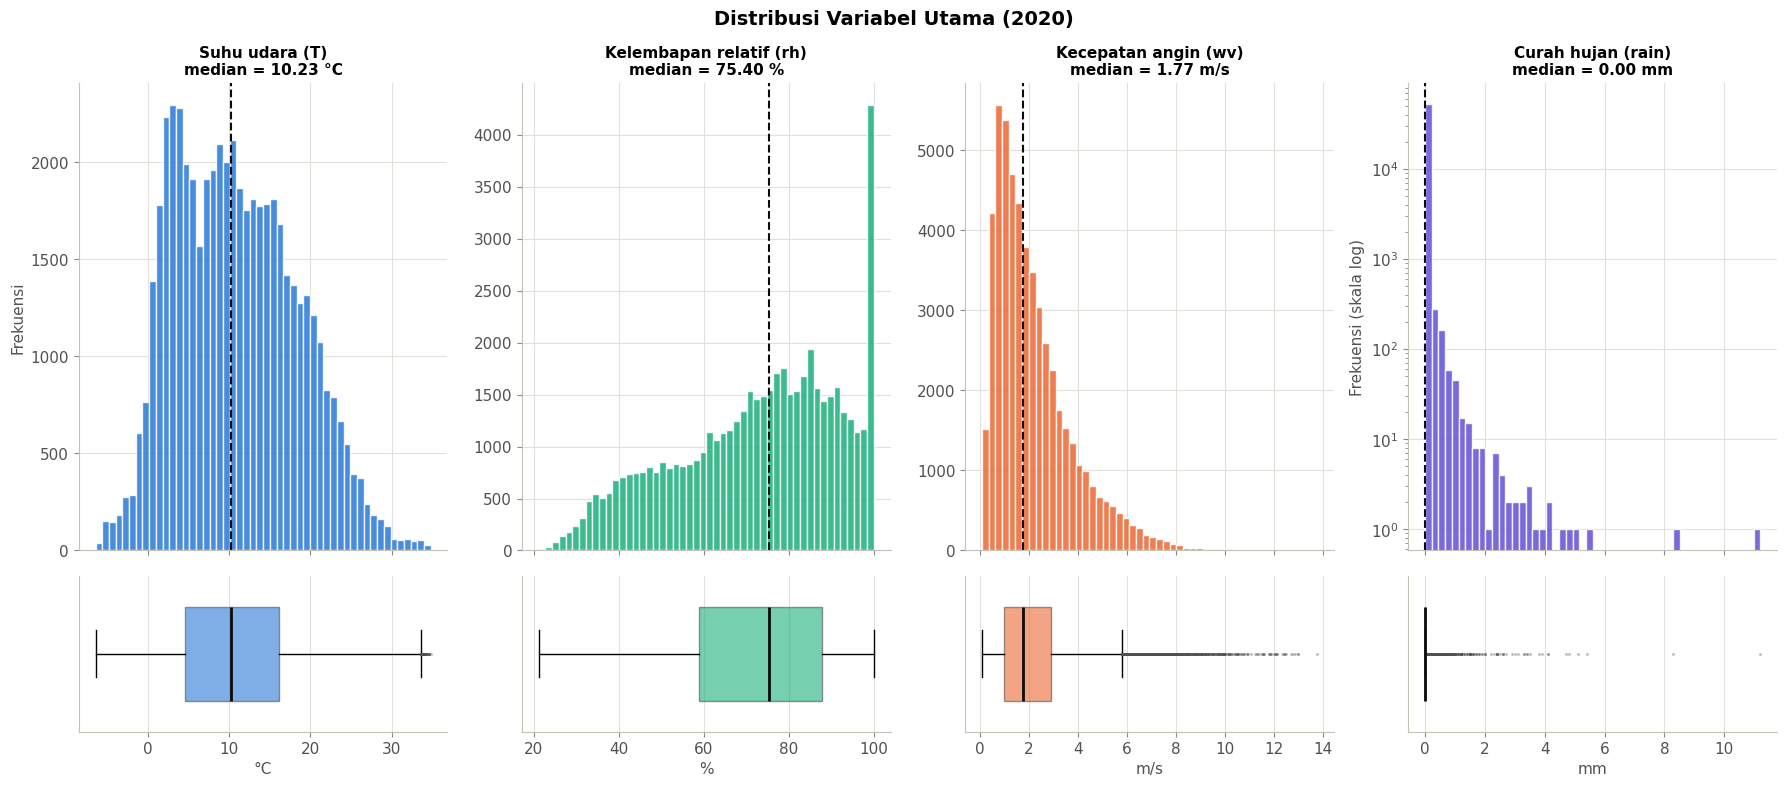

✓ eda_1_distribusi.png saved


,Mean,Median,Skewness,Kurtosis
T,10.82,10.23,0.33,-0.54
rh,72.49,75.40,-0.45,-0.75
wv,2.19,1.77,1.46,2.76
rain,0.01,0.00,34.93,2099.59


Interval 10 menit tanpa hujan (rain = 0): 96.4%


In [ ]:
print('Generating eda_1_distribusi.png...')

VAR_DIST = {   # kolom: (judul, satuan, warna)
    'T':    ('Suhu udara (T)',          '°C',  BIRU),
    'rh':   ('Kelembapan relatif (rh)', '%',   TOSKA),
    'wv':   ('Kecepatan angin (wv)',    'm/s', ORANYE),
    'rain': ('Curah hujan (rain)',      'mm',  UNGU),
}

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex='col',
                         gridspec_kw={'height_ratios': [3, 1]})

for i, (kol, (judul, satuan, warna)) in enumerate(VAR_DIST.items()):
    data = df[kol].dropna()

    # Baris atas: histogram
    ax = axes[0, i]
    ax.hist(data, bins=50, color=warna, alpha=0.85, edgecolor='white')
    ax.axvline(data.median(), color=TINTA, linestyle='--', linewidth=1.5)
    ax.set_title(f'{judul}\nmedian = {data.median():.2f} {satuan}', fontsize=11)
    if kol == 'rain':
        ax.set_yscale('log')   # hujan didominasi nilai 0, skala log agar sisanya terlihat
        ax.set_ylabel('Frekuensi (skala log)')
    elif i == 0:
        ax.set_ylabel('Frekuensi')

    # Baris bawah: boxplot horizontal
    axb = axes[1, i]
    axb.boxplot(data, vert=False, widths=0.6, patch_artist=True,
                boxprops=dict(facecolor=warna, alpha=0.6, edgecolor=TINTA_2),
                medianprops=dict(color=TINTA, linewidth=2),
                flierprops=dict(marker='o', markersize=2, markerfacecolor=TINTA_2,
                                markeredgecolor='none', alpha=0.4))
    axb.set_yticks([])
    axb.set_xlabel(satuan)
    axb.grid(axis='y', visible=False)

fig.suptitle(f'Distribusi Variabel Utama ({TAHUN})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_1_distribusi.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ eda_1_distribusi.png saved')

# Tabel pendamping: ukuran bentuk distribusi
tabel_dist = pd.DataFrame({
    'Mean':     df[list(VAR_DIST)].mean(),
    'Median':   df[list(VAR_DIST)].median(),
    'Skewness': df[list(VAR_DIST)].skew(),
    'Kurtosis': df[list(VAR_DIST)].kurt(),
}).round(2)
display(tabel_dist)

persen_nol = (df['rain'] == 0).mean() * 100
print(f'Interval 10 menit tanpa hujan (rain = 0): {persen_nol:.1f}%')

**Interpretasi:**
- **Suhu (`T`)** hampir simetris dengan kemiringan ringan ke kanan (skewness 0,33; mean 10,82 °C sedikit di atas median 10,23 °C). Kurtosis negatif (−0,54) berarti sebarannya lebih landai dan lebar daripada distribusi normal. Ini wajar karena satu tahun data mencakup empat musim dengan rentang suhu yang jauh, dari sekitar −6 °C sampai 35 °C. Boxplot nyaris tanpa titik ekstrem.
- **Kelembapan (`rh`)** miring ke kiri (skewness −0,45; mean 72,49 % di bawah median 75,40 %). Udara lebih sering lembap daripada kering. Ada lonjakan tajam di nilai 100 %, karena kelembapan relatif tidak bisa melebihi batas jenuh sehingga data menumpuk di ujung (kondisi berkabut, hujan, atau udara jenuh).
- **Kecepatan angin (`wv`)** miring kuat ke kanan (skewness 1,46, kurtosis 2,76). Hampir semua pengamatan berkisar 1 sampai 3 m/s, dan angin kencang di atas ±6 m/s muncul sebagai deretan titik di boxplot. Mean (2,19 m/s) lebih besar dari median (1,77 m/s) karena tertarik oleh kejadian angin kencang yang jarang.
- **Curah hujan (`rain`)** adalah variabel yang paling timpang. **96,4 %** interval 10 menit tidak hujan sama sekali, sehingga median 0 mm. Skewness 34,93 dan kurtosis 2.099,59 sangat ekstrem karena sebagian kecil interval mencatat hujan deras (maksimum 11,2 mm per 10 menit). Histogram hujan harus memakai skala log agar kejadian langka tetap terlihat.
- **Implikasi analisis:** `rain` dan `wv` tidak berdistribusi normal, jadi rata-rata saja tidak cukup menggambarkannya. Untuk hujan dipakai total (*sum*) seperti di bagian 2.2, dan outlier pada kedua variabel ini perlu diperiksa dulu di 1.5 sebelum diputuskan dibuang atau dipertahankan.

### 1.5 Analisis Outlier

Outlier dideteksi dengan metode **IQR**: nilai di luar rentang `Q1 − 1,5×IQR` sampai `Q3 + 1,5×IQR` ditandai sebagai outlier. Metode ini dipilih karena tidak mengasumsikan sebaran normal, sedangkan variabel seperti `wv` dan `rain` jelas miring. Outlier statistik belum tentu salah, jadi dilakukan juga pemeriksaan kewajaran fisik (misalnya kelembapan tidak mungkin di atas 100 %).

Generating eda_2_outlier.png...
=== DETEKSI OUTLIER (METODE IQR) ===
Catatan: untuk 'rain', persen dihitung dari interval yang hujan saja (rain > 0).


,Q1,Q3,IQR,Batas bawah,Batas atas,Jumlah outlier,Persen (%)
Variabel,,,,,,,
T,4.59,16.18,11.59,-12.79,33.56,52,0.10
Tdew,0.78,9.70,8.92,-12.60,23.08,9,0.02
rh,58.82,87.90,29.08,15.20,131.52,0,0.00
p,984.80,995.93,11.13,968.10,1012.62,1322,2.51
wv,1.00,2.92,1.92,-1.88,5.80,2020,3.83
max. wv,1.77,4.85,3.08,-2.85,9.47,1618,3.07
rain,0.10,0.30,0.20,-0.20,0.60,182,9.52
SWDR,0.00,182.90,182.90,-274.35,457.25,5714,10.84


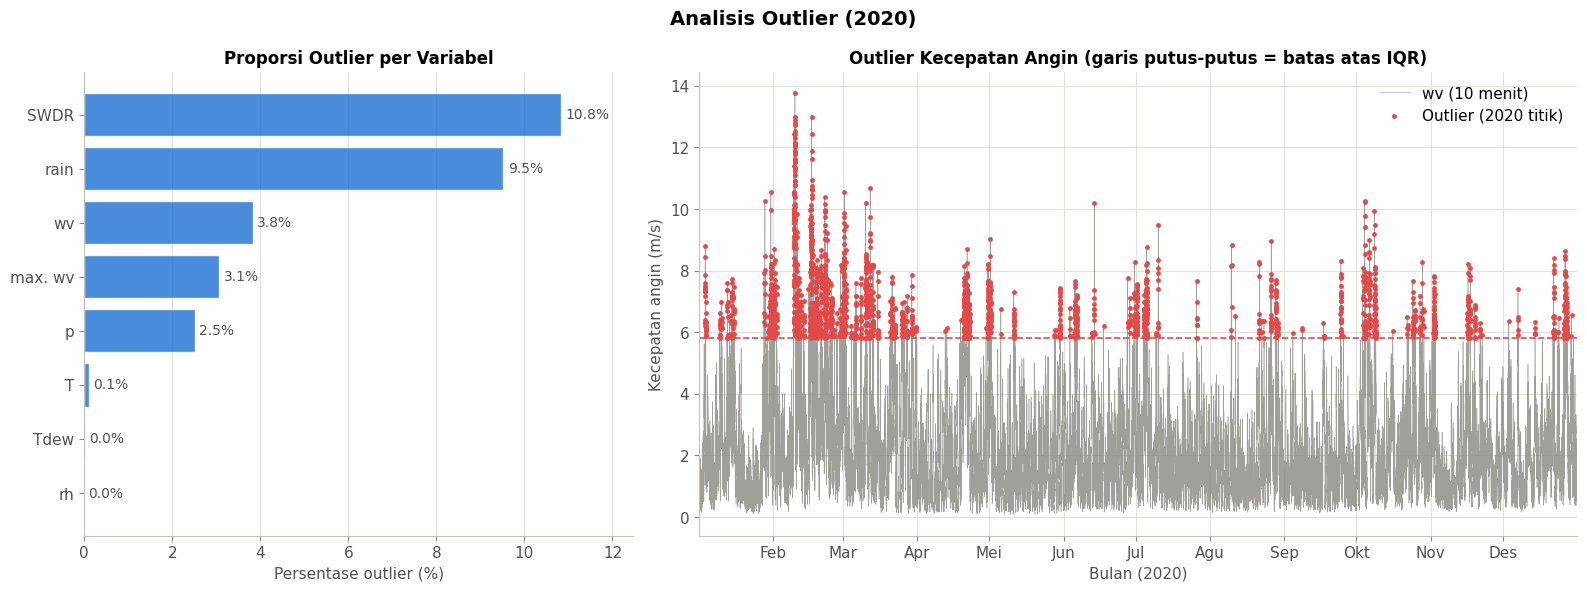

✓ eda_2_outlier.png saved

=== PEMERIKSAAN KEWAJARAN FISIK ===


,Pelanggaran
Aturan,
rh di luar 0-100 %,0
wv < 0,0
max. wv < 0,0
rain < 0,0
wd di luar 0-360 derajat,0
SWDR < 0,0
wv > max. wv,0



5 nilai tertinggi max. wv (hembusan angin terkuat):
date
2020-02-16 22:30:00    22.90
2020-02-10 00:50:00    22.41
2020-02-09 23:50:00    21.03
2020-02-10 03:20:00    20.03
2020-02-10 02:50:00    19.91


In [ ]:
print('Generating eda_2_outlier.png...')

VAR_OUT = ['T', 'Tdew', 'rh', 'p', 'wv', 'max. wv', 'rain', 'SWDR']


def batas_iqr(seri, abaikan_nol=False):
    """Hitung Q1, Q3, IQR, dan batas bawah/atas. abaikan_nol=True: hitung hanya dari nilai > 0."""
    data = seri.dropna()
    if abaikan_nol:
        data = data[data > 0]
    q1, q3 = data.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr


baris, topeng = [], {}
for kol in VAR_OUT:
    # 'rain' didominasi nilai 0 (IQR = 0), jadi batas dihitung hanya dari interval yang benar-benar hujan
    abaikan_nol = (kol == 'rain')
    q1, q3, iqr, bawah, atas = batas_iqr(df[kol], abaikan_nol)
    mask = (df[kol] < bawah) | (df[kol] > atas)
    if abaikan_nol:
        mask &= df[kol] > 0
    topeng[kol] = mask
    n_valid = int(df[kol].notna().sum() - (int((df[kol] == 0).sum()) if abaikan_nol else 0))
    baris.append({
        'Variabel': kol, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Batas bawah': bawah, 'Batas atas': atas,
        'Jumlah outlier': int(mask.sum()),
        'Persen (%)': mask.sum() / n_valid * 100,
    })

tabel_outlier = pd.DataFrame(baris).set_index('Variabel').round(2)
print('=== DETEKSI OUTLIER (METODE IQR) ===')
print("Catatan: untuk 'rain', persen dihitung dari interval yang hujan saja (rain > 0).")
display(tabel_outlier)

# ---------- Grafik ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.6]})

# Panel kiri: persentase outlier per variabel
urut = tabel_outlier['Persen (%)'].sort_values()
ax1.barh(urut.index, urut.values, color=BIRU, alpha=0.85, edgecolor='white')
for i, v in enumerate(urut.values):
    ax1.text(v + 0.1, i, f'{v:.1f}%', va='center', fontsize=10, color=TINTA_2)
ax1.set_xlabel('Persentase outlier (%)')
ax1.set_title('Proporsi Outlier per Variabel', fontsize=12)
ax1.set_xlim(0, urut.max() * 1.15)
ax1.grid(axis='y', visible=False)

# Panel kanan: kecepatan angin, outlier ditandai merah
ax2.plot(df.index, df['wv'], linewidth=0.4, color='#898781', alpha=0.8, label='wv (10 menit)')
out_wv = df.loc[topeng['wv'], 'wv']
ax2.scatter(out_wv.index, out_wv.values, s=6, color=MERAH, label=f'Outlier ({len(out_wv)} titik)', zorder=3)
ax2.axhline(tabel_outlier.loc['wv', 'Batas atas'], color=MERAH, linestyle='--', linewidth=1.2)
ax2.set_xlabel(f'Bulan ({TAHUN})')
ax2.set_ylabel('Kecepatan angin (m/s)')
ax2.set_title('Outlier Kecepatan Angin (garis putus-putus = batas atas IQR)', fontsize=12)
format_sumbu_bulan(ax2)
ax2.set_xlim(df.index[0], df.index[-1])
ax2.legend(loc='upper right')

fig.suptitle(f'Analisis Outlier ({TAHUN})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_2_outlier.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ eda_2_outlier.png saved')

# ---------- Pemeriksaan kewajaran fisik ----------
cek_fisik = pd.DataFrame({
    'Aturan': [
        'rh di luar 0-100 %',
        'wv < 0',
        'max. wv < 0',
        'rain < 0',
        'wd di luar 0-360 derajat',
        'SWDR < 0',
        'wv > max. wv',
    ],
    'Pelanggaran': [
        int(((df['rh'] < 0) | (df['rh'] > 100)).sum()),
        int((df['wv'] < 0).sum()),
        int((df['max. wv'] < 0).sum()),
        int((df['rain'] < 0).sum()),
        int(((df['wd'] < 0) | (df['wd'] > 360)).sum()),
        int((df['SWDR'] < 0).sum()),
        int((df['wv'] > df['max. wv']).sum()),
    ],
}).set_index('Aturan')
print('\n=== PEMERIKSAAN KEWAJARAN FISIK ===')
display(cek_fisik)

print('\n5 nilai tertinggi max. wv (hembusan angin terkuat):')
print(df['max. wv'].nlargest(5).to_string())

**Interpretasi:**
- **Proporsi outlier terbesar ada di `SWDR` (10,8 %) dan `rain` (9,5 %)**, tetapi keduanya bukan error. Radiasi matahari bernilai 0 pada malam hari dan tinggi pada siang hari, sehingga distribusinya terpecah dua dan batas atas IQR (±457 W/m²) menandai siang hari yang cerah sebagai "outlier". Hujan serupa: 96,4 % interval tidak hujan, jadi interval yang benar-benar hujan deras tampak ekstrem. Untuk `rain`, batas IQR dan persennya dihitung hanya dari interval yang hujan (rain > 0).
- **Kecepatan angin (`wv`) memiliki 2.020 outlier (3,8 %)**, dengan batas atas 5,80 m/s. Grafik menunjukkan outlier mengelompok pada periode tertentu, paling padat di **Februari** dengan puncak sekitar 13,8 m/s, dan klaster yang lebih kecil di beberapa bulan lain (antara lain Mei, Juli, dan Oktober). Pola berkelompok seperti ini khas kejadian cuaca (angin kencang berlangsung berjam-jam sampai berhari-hari), bukan gangguan sensor yang muncul acak. Penyebab pasti tiap klaster tidak bisa dipastikan dari data ini.
- **Suhu (`T`) hanya 52 outlier (0,1 %)**, seluruhnya di sisi atas (di atas 33,56 °C) karena suhu minimum −6,44 °C masih di dalam batas bawah (−12,79 °C). Titik tertinggi 34,80 °C tercatat pada 8 Agustus 2020. **Titik embun (`Tdew`) hanya 9 outlier**, semuanya di sisi bawah (di bawah −12,60 °C).
- **Kelembapan (`rh`) tidak punya outlier** (0 %). Batas atas IQR-nya (131,5 %) bahkan tidak mungkin tercapai secara fisik, jadi untuk `rh` batas fisik 0 sampai 100 % lebih bermakna daripada IQR.
- **Tekanan udara (`p`) memiliki 1.322 outlier (2,5 %)** di kedua sisi (minimum 955,58 dan maksimum 1020,07 mbar). Nilai ini masih dalam rentang tekanan atmosfer yang wajar dan menandai periode tekanan rendah atau tinggi yang cukup kuat.
- **Pemeriksaan kewajaran fisik:** ketujuh aturan menunjukkan 0 pelanggaran. Kelembapan berada dalam 0 sampai 100 %, `wv`, `max. wv`, `rain`, dan `SWDR` tidak ada yang negatif, `wd` berada dalam 0 sampai 360 derajat, dan `wv`

### 1.6 Korelasi Antar Variabel

Heatmap menunjukkan koefisien korelasi Pearson (r) antar seluruh 20 variabel. Nilai mendekati +1 berarti dua variabel naik-turun bersama, mendekati −1 berarti berlawanan, dan mendekati 0 berarti hampir tidak berhubungan. Pasangan dengan |r| ≥ 0,95 dicatat sebagai variabel yang redundan.

Generating eda_3_korelasi.png...


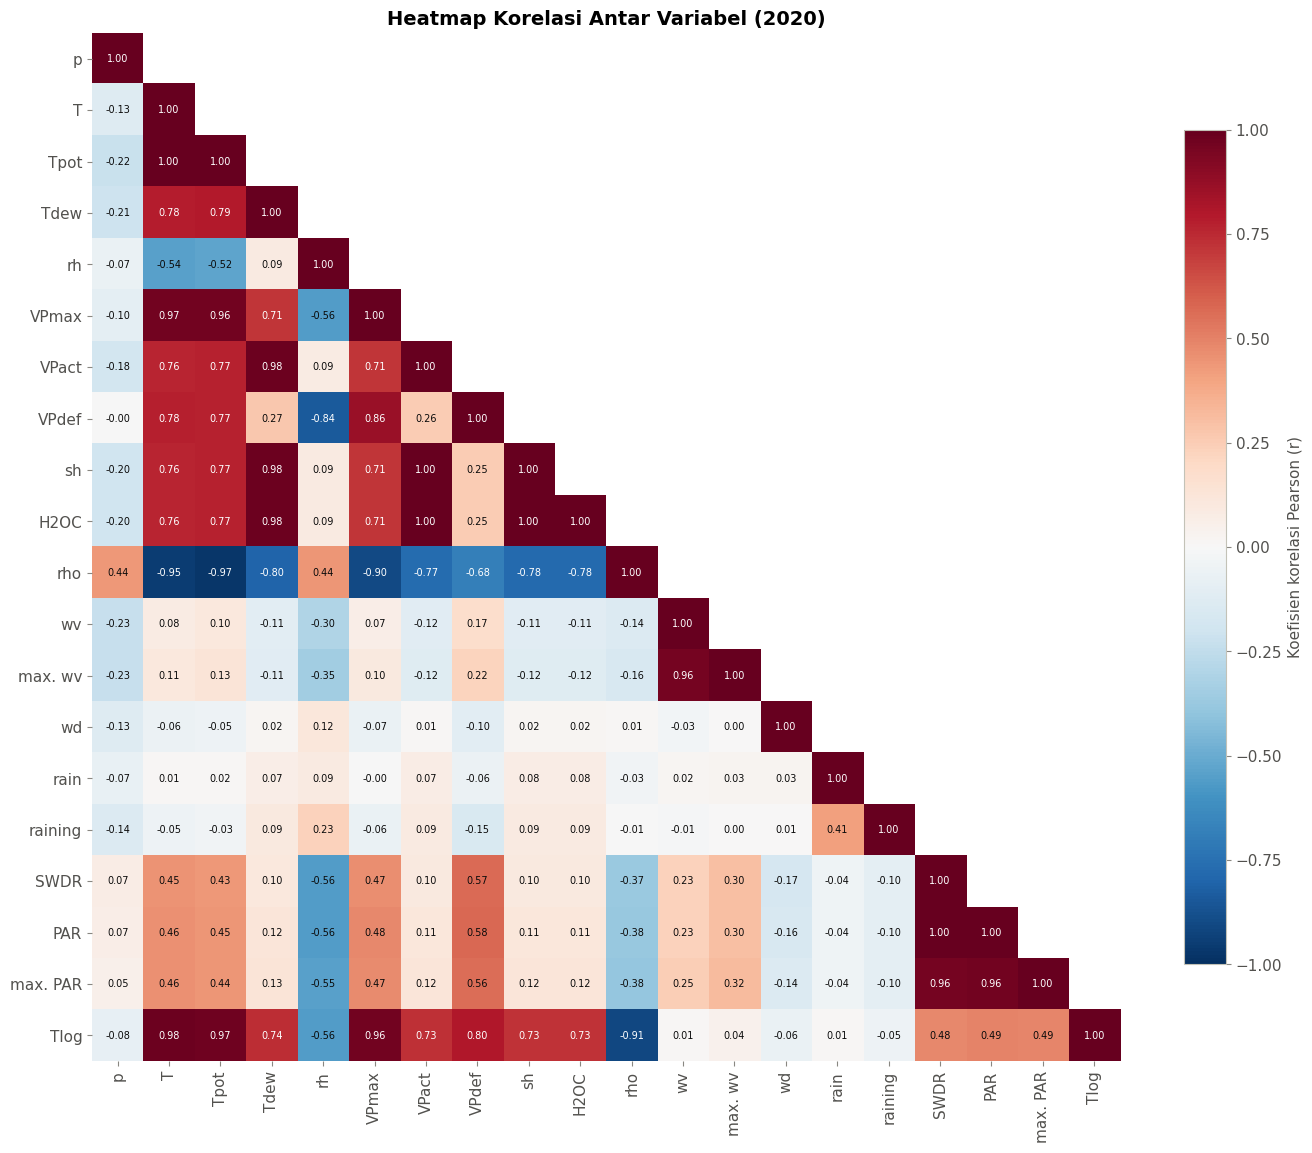

✓ eda_3_korelasi.png saved

Pasangan dengan |r| >= 0,95 (redundan): 17 dari 190 pasangan


,Variabel 1,Variabel 2,r
0,H2OC,sh,1.000
1,H2OC,VPact,1.000
2,sh,VPact,1.000
3,PAR,SWDR,0.999
4,Tpot,T,0.995
5,Tlog,T,0.982
6,VPact,Tdew,0.977
7,H2OC,Tdew,0.977
8,sh,Tdew,0.977
9,rho,Tpot,-0.973



Korelasi tiap variabel terhadap T (urut dari positif ke negatif):


,r dengan T
Tpot,0.995
Tlog,0.982
VPmax,0.968
Tdew,0.783
VPdef,0.780
VPact,0.763
H2OC,0.762
sh,0.762
PAR,0.460
max. PAR,0.457



Catatan: 'wd' (arah angin) adalah sudut melingkar (0 dan 360 derajat sama), jadi korelasi Pearson-nya kurang bermakna.


In [ ]:
print('Generating eda_3_korelasi.png...')

korelasi = df.corr(method='pearson')
kolom = list(korelasi.columns)
n = len(kolom)
segitiga_atas = np.triu(np.ones((n, n), dtype=bool), k=1)   # sembunyikan setengah atas (duplikat)

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(np.ma.masked_where(segitiga_atas, korelasi.values),
               cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(n))
ax.set_xticklabels(kolom, rotation=90)
ax.set_yticks(range(n))
ax.set_yticklabels(kolom)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)

for i in range(n):
    for j in range(i + 1):
        r = korelasi.iloc[i, j]
        ax.text(j, i, f'{r:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(r) > 0.6 else TINTA)

cbar = fig.colorbar(im, ax=ax, shrink=0.75)
cbar.set_label('Koefisien korelasi Pearson (r)')
ax.set_title(f'Heatmap Korelasi Antar Variabel ({TAHUN})', fontsize=14)
plt.tight_layout()
plt.savefig('eda_3_korelasi.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ eda_3_korelasi.png saved')

# ---------- Pasangan variabel dengan korelasi sangat tinggi ----------
pasangan = (korelasi.where(np.tril(np.ones((n, n), dtype=bool), k=-1))
            .stack().rename('r').reset_index())
pasangan.columns = ['Variabel 1', 'Variabel 2', 'r']
pasangan['|r|'] = pasangan['r'].abs()

tinggi = pasangan[pasangan['|r|'] >= 0.95].sort_values('|r|', ascending=False)
print(f'\nPasangan dengan |r| >= 0,95 (redundan): {len(tinggi)} dari {len(pasangan)} pasangan')
display(tinggi.head(15).drop(columns='|r|').round(3).reset_index(drop=True))

# ---------- Korelasi terhadap suhu udara (T) ----------
kor_T = korelasi['T'].drop('T').sort_values(ascending=False).round(3)
print('\nKorelasi tiap variabel terhadap T (urut dari positif ke negatif):')
display(kor_T.to_frame('r dengan T'))

print("\nCatatan: 'wd' (arah angin) adalah sudut melingkar (0 dan 360 derajat sama), "
      "jadi korelasi Pearson-nya kurang bermakna.")

**Interpretasi:**
- **Banyak variabel yang redundan.** Dari 190 pasangan variabel, 17 pasangan memiliki |r| ≥ 0,95. Tiga variabel uap air (`H2OC`, `sh`, `VPact`) saling berkorelasi 1,000, artinya ketiganya membawa informasi yang praktis sama. `PAR` dan `SWDR` (keduanya ukuran radiasi matahari) berkorelasi 0,999, sedangkan `wv` dan `max. wv` berkorelasi 0,96. Sebagian besar variabel ini secara fisik diturunkan dari suhu dan kelembapan, jadi korelasi setinggi ini memang diharapkan.
- **Kelompok suhu bergerak hampir identik.** `T` berkorelasi 0,995 dengan `Tpot`, 0,982 dengan `Tlog`, dan 0,968 dengan `VPmax`. Korelasi `Tlog` yang tinggi tidak bertentangan dengan temuan 2.3 bahwa `Tlog` rata-rata 10,7 °C lebih tinggi dari `T`: korelasi hanya mengukur kekompakan naik-turun, bukan selisih tingkat nilainya.
- **Kelompok titik embun dan uap air** (`Tdew`, `VPact`, `sh`, `H2OC`) berkorelasi 0,977 satu sama lain, dan berkorelasi sedang-kuat dengan `T` (0,76 sampai 0,78). Udara yang lebih hangat cenderung mengandung lebih banyak uap air.
- **Hubungan negatif terkuat dengan `T`** adalah `rho` (densitas udara, r = −0,947): udara hangat lebih renggang sehingga massa jenisnya turun. `rh` juga berkorelasi negatif sedang dengan `T` (−0,54) dan dengan `SWDR` (−0,56), serta sangat negatif dengan `VPdef` (−0,84), sejalan dengan kelembapan relatif yang turun saat udara menghangat dan kering.
- **Radiasi matahari hanya berkorelasi sedang dengan suhu** (`SWDR`, `PAR`, `max. PAR`: r sekitar 0,45 sampai 0,46). Radiasi bernilai 0 setiap malam, sedangkan suhu naik-turun lebih lambat mengikuti musim, jadi hubungannya tidak sekuat yang mungkin diduga.
- **Variabel yang nyaris tidak berkorelasi dengan apa pun:** `rain` (|r| ≤ 0,09 dengan semua variabel kecuali `raining`, 0,41), `wd` (|r| ≤ 0,17), dan `p` terhadap suhu (r = −0,13). Untuk `rain` dan `wv` yang sangat miring (bagian 1.4), korelasi Pearson cenderung merendahkan hubungan yang ada. Korelasi `wd` kurang bermakna karena arah angin adalah sudut melingkar.
- **Implikasi:** untuk analisis atau pemodelan lanjutan, tidak semua 20 variabel perlu dipakai. Satu wakil per kelompok sudah cukup, misalnya `T`, `rh`, `p`, `wv`, `rain`, dan `SWDR`, supaya tidak terjadi multikolinearitas. Ingat bahwa korelasi tidak membuktikan sebab-akibat.

## 2. Visualisasi Wajib (4 Plot)

### 2.1 Line Plot - Tren Suhu Udara Harian

Data 10-menit dirata-rata menjadi **suhu harian** (366 hari). Untuk suhu dipakai **mean**, bukan *sum* seperti revenue, karena suhu tidak bisa dijumlahkan.
Area tipis di belakang garis menunjukkan rentang suhu minimum–maksimum tiap hari.

Generating 1_line_plot.png...


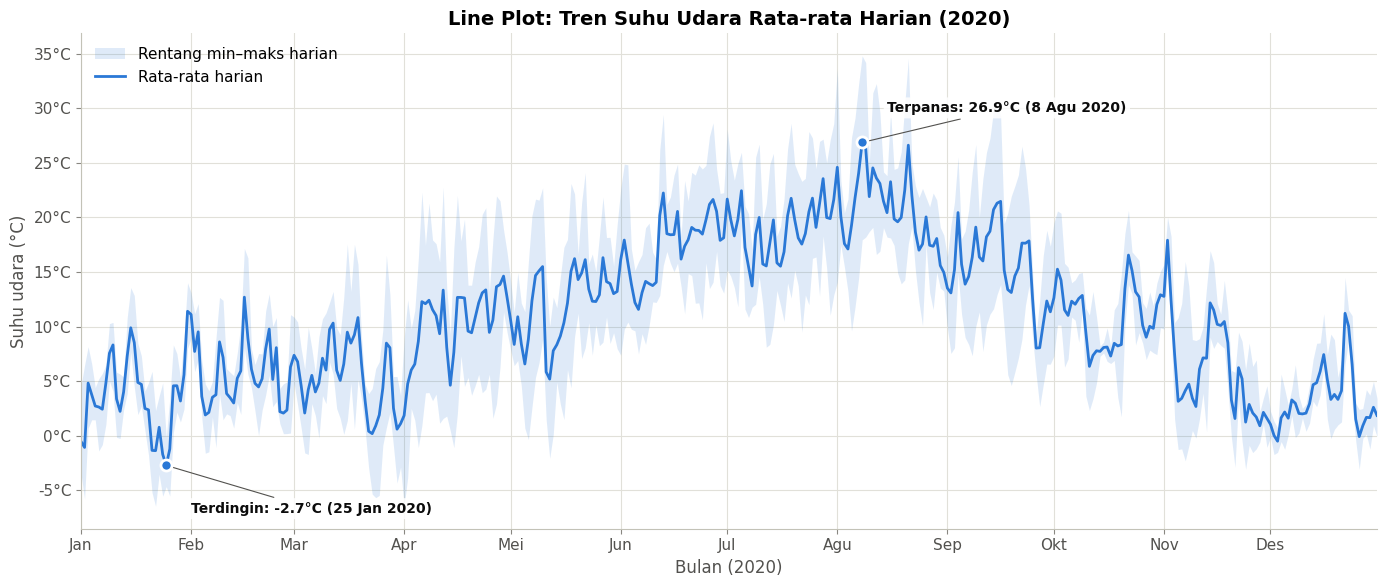

✓ 1_line_plot.png saved


,Rata-rata (°C),Minimum (°C),Maksimum (°C)
Jan,3.47,-6.44,14.02
Feb,5.76,-1.59,17.16
Mar,5.39,-5.66,17.57
Apr,10.39,-6.40,22.79
Mei,11.89,-2.06,24.11
Jun,17.36,7.39,29.44
Jul,18.96,8.12,28.62
Agu,20.76,9.60,34.80
Sep,15.41,2.68,30.16
Okt,10.87,1.74,20.65


Suhu rata-rata tahunan : 10.82 °C
Suhu terendah (10-menit): -6.44 °C pada 2020-01-22 06:50:00
Suhu tertinggi (10-menit): 34.80 °C pada 2020-08-08 15:40:00


In [ ]:
print('Generating 1_line_plot.png...')

suhu_harian = df['T'].resample('D').agg(['mean', 'min', 'max'])
suhu_harian.columns = ['T_mean', 'T_min', 'T_max']

hari_terpanas = suhu_harian['T_mean'].idxmax()
hari_terdingin = suhu_harian['T_mean'].idxmin()

fig, ax = plt.subplots(figsize=(14, 6))
ax.fill_between(suhu_harian.index, suhu_harian['T_min'], suhu_harian['T_max'],
                color=BIRU, alpha=0.15, linewidth=0, label='Rentang min–maks harian')
ax.plot(suhu_harian.index, suhu_harian['T_mean'],
        linewidth=2, color=BIRU, label='Rata-rata harian')

# Label selektif: hanya hari terpanas & terdingin
for tgl, judul, offset in [(hari_terpanas, 'Terpanas', (18, 22)),
                           (hari_terdingin, 'Terdingin', (18, -34))]:
    nilai = suhu_harian.loc[tgl, 'T_mean']
    ax.plot(tgl, nilai, 'o', markersize=8, color=BIRU,
            markeredgecolor='white', markeredgewidth=2, zorder=5)
    ax.annotate(f'{judul}: {nilai:.1f}°C ({tgl_id(tgl)})', xy=(tgl, nilai),
                xytext=offset, textcoords='offset points', fontsize=10,
                fontweight='bold', color=TINTA,
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.85),
                arrowprops=dict(arrowstyle='-', color=TINTA_2, lw=0.8))

ax.set_xlabel(f'Bulan ({TAHUN})', fontsize=12)
ax.set_ylabel('Suhu udara (°C)', fontsize=12)
ax.set_title(f'Line Plot: Tren Suhu Udara Rata-rata Harian ({TAHUN})', fontsize=14)
format_sumbu_bulan(ax)
format_celsius(ax)
ax.set_xlim(suhu_harian.index[0], suhu_harian.index[-1])
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('1_line_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ 1_line_plot.png saved')

# Tabel pendamping (ringkasan bulanan)
ringkasan_bulanan = df['T'].groupby(df.index.month).agg(['mean', 'min', 'max']).round(2)
ringkasan_bulanan.index = BULAN_ID
ringkasan_bulanan.columns = ['Rata-rata (°C)', 'Minimum (°C)', 'Maksimum (°C)']
display(ringkasan_bulanan)
print(f'Suhu rata-rata tahunan : {df["T"].mean():.2f} °C')
print(f'Suhu terendah (10-menit): {df["T"].min():.2f} °C pada {df["T"].idxmin()}')
print(f'Suhu tertinggi (10-menit): {df["T"].max():.2f} °C pada {df["T"].idxmax()}')

**Interpretasi:**
- Suhu mengikuti **siklus musiman tahunan**. Suhu rendah di Jan–Mar (rata-rata bulanan 3,5–5,8 °C), naik mulai April, mencapai puncak di Jun–Agu (17,4–20,8 °C), lalu turun lagi hingga Desember (3,3 °C).
- Hari terdingin adalah **25 Jan 2020** (rata-rata −2,7 °C) dan hari terpanas **8 Agu 2020** (rata-rata 26,9 °C). Dalam data 10-menit, suhu terendah −6,4 °C (22 Jan) dan tertinggi **34,8 °C** (8 Agu).
- Garis harian cukup "bergerigi". Simpangan baku perubahan suhu dari hari ke hari sekitar 2,4 °C. Noise ini yang nanti dihaluskan dengan *moving average* (bagian 3.1).

### 2.2 Area Plot - Curah Hujan Bulanan per Periode Waktu (Stacked)

Dataset cuaca tidak punya kolom kategori seperti `Category`. Karena itu dibuat kategori **periode waktu** dari jam pencatatan. Curah hujan dijumlahkan (*sum*) per bulan, sehingga tinggi tumpukan = total hujan bulan tersebut.

Generating 2_area_plot.png...


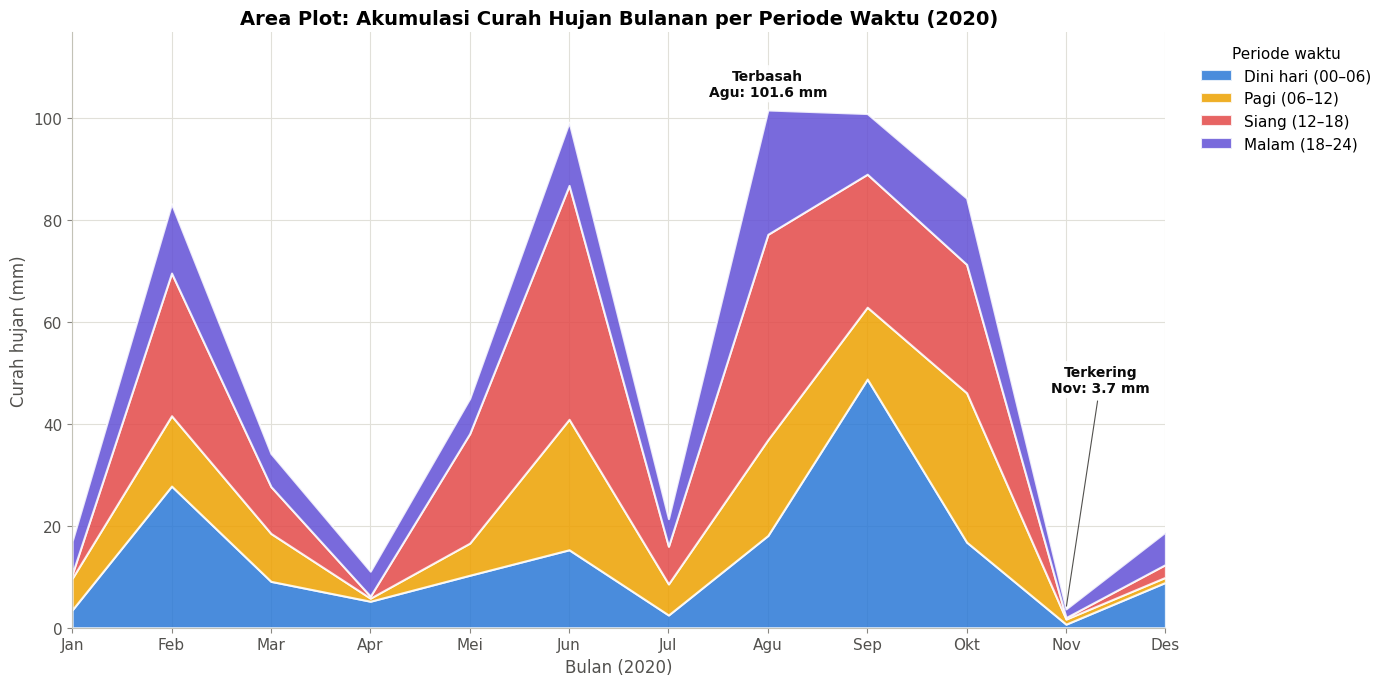

✓ 2_area_plot.png saved


,Dini hari (00–06),Pagi (06–12),Siang (12–18),Malam (18–24),Total (mm)
Jan,3.5,6.2,0.8,6.5,17.0
Feb,27.8,13.8,28.0,13.6,83.2
Mar,9.1,9.4,9.2,6.5,34.2
Apr,5.2,0.6,0.4,4.9,11.1
Mei,10.3,6.3,21.5,6.9,45.0
Jun,15.3,25.6,45.9,12.4,99.2
Jul,2.5,6.1,7.4,5.4,21.4
Agu,18.1,18.8,40.3,24.4,101.6
Sep,48.8,14.1,26.1,11.9,100.9
Okt,16.8,29.3,25.2,13.0,84.3


Kontribusi tiap periode terhadap total hujan setahun (%):
Dini hari (00–06)    26.9
Pagi (06–12)         21.3
Siang (12–18)        33.5
Malam (18–24)        18.3


In [ ]:
print('Generating 2_area_plot.png...')

PERIODE = ['Dini hari (00–06)', 'Pagi (06–12)', 'Siang (12–18)', 'Malam (18–24)']
WARNA_PERIODE = [BIRU, KUNING, MERAH, UNGU]

periode = pd.cut(df.index.hour, bins=[0, 6, 12, 18, 24], right=False, labels=PERIODE)
hujan_bulanan = (df['rain']
                 .groupby([df.index.month, periode], observed=False)
                 .sum()
                 .unstack(fill_value=0)[PERIODE])

fig, ax = plt.subplots(figsize=(14, 7))
ax.stackplot(hujan_bulanan.index, hujan_bulanan.T.values, labels=PERIODE,
             colors=WARNA_PERIODE, alpha=0.85, edgecolor='white', linewidth=1.5)

# Label selektif: total bulan terbasah (di atas puncak) & terkering (pakai garis penunjuk)
total_bulanan = hujan_bulanan.sum(axis=1)
bulan_basah, bulan_kering = total_bulanan.idxmax(), total_bulanan.idxmin()
gaya_label = dict(ha='center', fontsize=10, fontweight='bold', color=TINTA,
                  bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.9))
ax.annotate(f'Terbasah\n{BULAN_ID[bulan_basah - 1]}: {total_bulanan[bulan_basah]:.1f} mm',
            xy=(bulan_basah, total_bulanan[bulan_basah]), xytext=(0, 8),
            textcoords='offset points', va='bottom', **gaya_label)
ax.annotate(f'Terkering\n{BULAN_ID[bulan_kering - 1]}: {total_bulanan[bulan_kering]:.1f} mm',
            xy=(bulan_kering, total_bulanan[bulan_kering]),
            xytext=(min(bulan_kering + 0.35, 11.6), total_bulanan.max() * 0.45),
            textcoords='data', va='bottom',
            arrowprops=dict(arrowstyle='-', color=TINTA_2, lw=0.8), **gaya_label)

ax.set_xlabel(f'Bulan ({TAHUN})', fontsize=12)
ax.set_ylabel('Curah hujan (mm)', fontsize=12)
ax.set_title(f'Area Plot: Akumulasi Curah Hujan Bulanan per Periode Waktu ({TAHUN})', fontsize=14)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(BULAN_ID)
ax.set_xlim(1, 12)
ax.set_ylim(0, total_bulanan.max() * 1.15)
ax.legend(title='Periode waktu', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('2_area_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ 2_area_plot.png saved')

# Tabel pendamping
tabel_hujan = hujan_bulanan.copy()
tabel_hujan.columns = list(tabel_hujan.columns)
tabel_hujan['Total (mm)'] = total_bulanan
tabel_hujan.index = BULAN_ID
display(tabel_hujan.round(1))
kontribusi = (hujan_bulanan.sum() / hujan_bulanan.values.sum() * 100).round(1)
print('Kontribusi tiap periode terhadap total hujan setahun (%):')
print(kontribusi.to_string())

**Interpretasi:**
- Total hujan 2020 sebesar **620,4 mm**. Bulan terbasah adalah **Agustus (101,6 mm)**, hampir sama dengan September (100,9 mm) dan Juni (99,2 mm). Bulan terkering adalah **November (3,7 mm)**.
- Periode **siang (12–18)** menyumbang porsi terbesar, **33,5 %** dari total hujan. Urutan berikutnya dini hari (26,9 %), pagi (21,3 %), dan malam (18,3 %).
- Pada bulan-bulan musim panas (Jun–Agu), hujan siang paling dominan. Ini konsisten dengan hujan konvektif (badai sore hari akibat pemanasan permukaan), walaupun penyebabnya tidak bisa dipastikan hanya dari data ini. Sebaliknya, hujan September lebih banyak turun pada dini hari.

### 2.3 Multiple Time Series - Perbandingan Variabel Suhu (Direct Labeling)

Tiga variabel bersatuan sama (°C) dibandingkan dalam satu sumbu: suhu udara `T`, titik embun `Tdew`, dan suhu logger `Tlog`.
Label ditempel langsung di ujung tiap garis (*direct labeling*), jadi pembaca tidak perlu mencocokkan warna dengan legenda.

Generating 3_multiple_series.png...


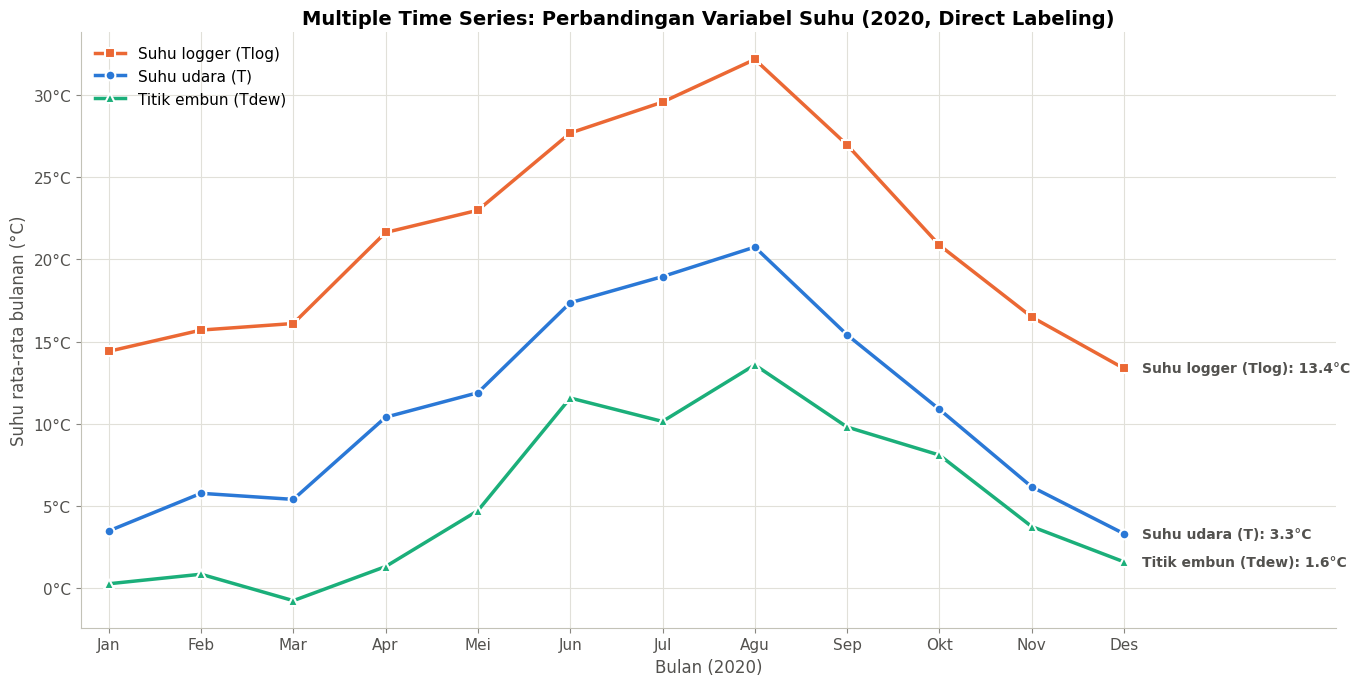

✓ 3_multiple_series.png saved


,Tlog,T,Tdew,T - Tdew,rh (%)
Jan,14.41,3.47,0.25,3.22,80.23
Feb,15.70,5.76,0.83,4.93,71.46
Mar,16.10,5.39,-0.78,6.17,66.77
Apr,21.64,10.39,1.30,9.10,56.11
Mei,23.00,11.89,4.70,7.18,64.10
Jun,27.70,17.36,11.56,5.80,71.91
Jul,29.59,18.96,10.13,8.82,59.99
Agu,32.19,20.76,13.58,7.18,67.40
Sep,26.98,15.41,9.79,5.62,72.88
Okt,20.87,10.87,8.09,2.78,84.17


Rata-rata selisih Tlog - T: 10.7 °C


In [ ]:
print('Generating 3_multiple_series.png...')

SERI_SUHU = {                     # kolom: (nama tampilan, warna, marker)
    'Tlog': ('Suhu logger (Tlog)', ORANYE, 's'),
    'T':    ('Suhu udara (T)',     BIRU,   'o'),
    'Tdew': ('Titik embun (Tdew)', TOSKA,  '^'),
}
suhu_bulanan = df[list(SERI_SUHU)].groupby(df.index.month).mean()

fig, ax = plt.subplots(figsize=(14, 7))
for kolom, (nama, warna, marker) in SERI_SUHU.items():
    ax.plot(suhu_bulanan.index, suhu_bulanan[kolom], linewidth=2.5, color=warna,
            marker=marker, markersize=7, markeredgecolor='white', markeredgewidth=1.5,
            label=nama)
    # Direct label: nama + nilai di ujung garis (teks pakai warna tinta, bukan warna garis)
    x_akhir, y_akhir = suhu_bulanan.index[-1], suhu_bulanan[kolom].iloc[-1]
    ax.text(x_akhir + 0.2, y_akhir, f'{nama}: {y_akhir:.1f}°C',
            fontsize=10, fontweight='bold', va='center', color=TINTA_2)

ax.set_xlabel(f'Bulan ({TAHUN})', fontsize=12)
ax.set_ylabel('Suhu rata-rata bulanan (°C)', fontsize=12)
ax.set_title(f'Multiple Time Series: Perbandingan Variabel Suhu ({TAHUN}, Direct Labeling)', fontsize=14)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(BULAN_ID)
ax.set_xlim(0.7, 14.3)            # ruang kosong di kanan untuk label
format_celsius(ax)
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('3_multiple_series.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ 3_multiple_series.png saved')

# Tabel pendamping: selisih T - Tdew (makin besar = udara makin kering)
tabel_suhu = suhu_bulanan.copy()
tabel_suhu['T - Tdew'] = tabel_suhu['T'] - tabel_suhu['Tdew']
tabel_suhu['rh (%)'] = df['rh'].groupby(df.index.month).mean()
tabel_suhu.index = BULAN_ID
display(tabel_suhu.round(2))
print(f'Rata-rata selisih Tlog - T: {(df["Tlog"] - df["T"]).mean():.1f} °C')

**Interpretasi:**
- Ketiga variabel suhu **bergerak searah** dengan pola musiman yang sama: rendah di awal & akhir tahun, puncak di Agustus.
- `Tlog` selalu paling tinggi, rata-rata **10,7 °C di atas suhu udara**. Wajar, karena `Tlog` adalah suhu di dalam kotak *data logger* yang ikut terpanaskan oleh perangkat elektronik dan sinar matahari. Jadi `Tlog` bukan ukuran suhu lingkungan.
- Jarak `T` dengan `Tdew` menunjukkan seberapa kering udara. Jarak terbesar terjadi di **April (±9,1 °C, kelembapan 56 %)**, artinya udara paling kering. Jarak terkecil di **Desember (±1,7 °C, kelembapan 89 %)**, artinya udara hampir jenuh.

### 2.4 Seasonal Plot - Pola Suhu Harian (per Jam) per Musim

Data hanya mencakup **1 tahun (2020)**, jadi seasonal plot "pola bulanan per tahun" tidak bisa dibuat karena butuh minimal 2 tahun untuk dibandingkan.
Untuk data 10-menit, musiman yang paling kuat adalah **siklus harian (24 jam)**. Karena itu sumbu-x memakai **jam**, dan tiap garis mewakili satu **musim meteorologis**. Stasiun berada di Jerman (belahan bumi utara) yang memiliki 4 musim.

Generating 4_seasonal_plot.png...


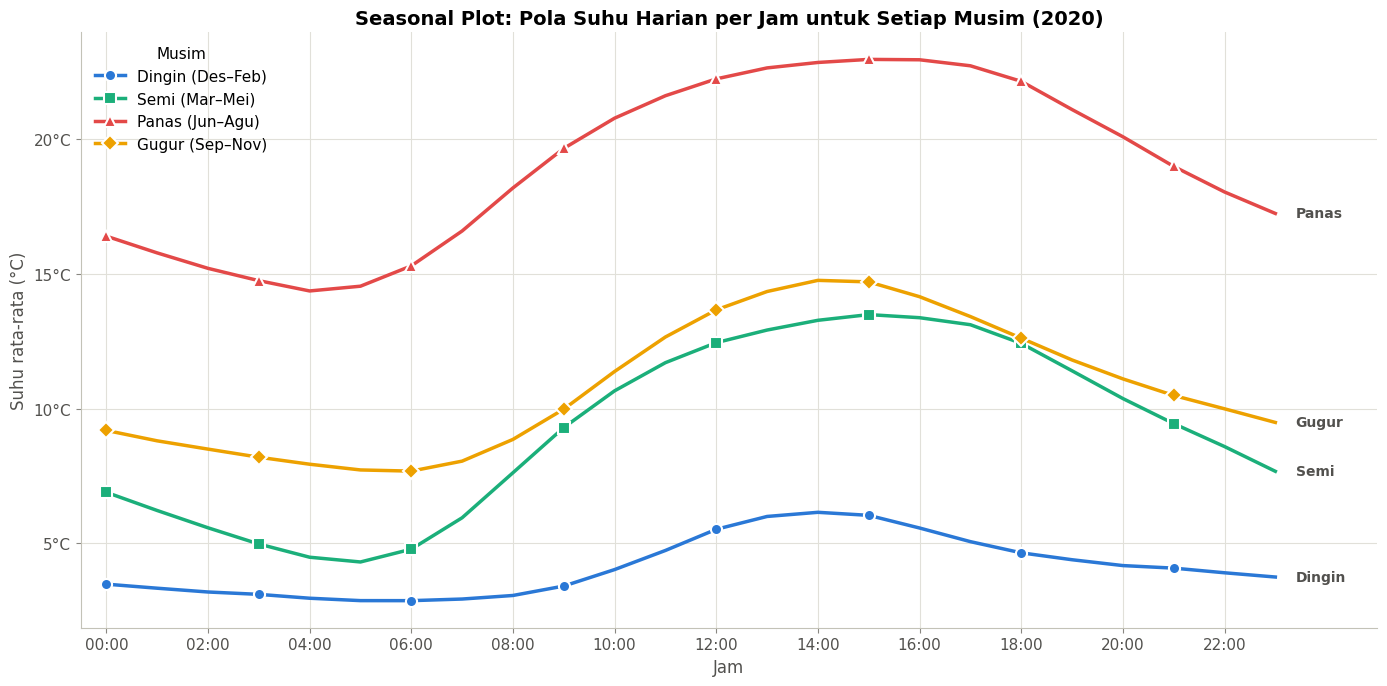

✓ 4_seasonal_plot.png saved


,Jam terdingin,Suhu min (°C),Jam terpanas,Suhu maks (°C),Amplitudo (°C)
Musim,,,,,
Dingin (Des–Feb),06:00,2.87,14:00,6.15,3.28
Semi (Mar–Mei),05:00,4.31,15:00,13.49,9.18
Panas (Jun–Agu),04:00,14.36,15:00,22.96,8.59
Gugur (Sep–Nov),06:00,7.68,14:00,14.76,7.08


In [ ]:
print('Generating 4_seasonal_plot.png...')

MUSIM = {                          # nama: (bulan, warna, marker)
    'Dingin (Des–Feb)': ([12, 1, 2],  BIRU,   'o'),
    'Semi (Mar–Mei)':   ([3, 4, 5],   TOSKA,  's'),
    'Panas (Jun–Agu)':  ([6, 7, 8],   MERAH,  '^'),
    'Gugur (Sep–Nov)':  ([9, 10, 11], KUNING, 'D'),
}
peta_musim = {b: nama for nama, (daftar_bulan, _, _) in MUSIM.items() for b in daftar_bulan}
musim = df.index.month.map(peta_musim).rename('Musim')
jam = df.index.hour.rename('Jam')

seasonal_data = (df['T']
                 .groupby([musim, jam])
                 .mean()
                 .unstack(level=0)[list(MUSIM)])

fig, ax = plt.subplots(figsize=(14, 7))
for nama, (_, warna, marker) in MUSIM.items():
    y = seasonal_data[nama]
    ax.plot(seasonal_data.index, y, linewidth=2.5, color=warna, marker=marker,
            markersize=8, markevery=3, markeredgecolor='white', markeredgewidth=1.5,
            label=nama)
    ax.text(23.4, y.iloc[-1], nama.split()[0], fontsize=10, fontweight='bold',
            va='center', color=TINTA_2)

ax.set_xlabel('Jam', fontsize=12)
ax.set_ylabel('Suhu rata-rata (°C)', fontsize=12)
ax.set_title(f'Seasonal Plot: Pola Suhu Harian per Jam untuk Setiap Musim ({TAHUN})', fontsize=14)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f'{j:02d}:00' for j in range(0, 24, 2)])
ax.set_xlim(-0.5, 25)
format_celsius(ax)
ax.legend(title='Musim', loc='upper left')
plt.tight_layout()
plt.savefig('4_seasonal_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ 4_seasonal_plot.png saved')

# Tabel pendamping: jam terdingin/terpanas & amplitudo harian
tabel_musim = pd.DataFrame({
    'Jam terdingin': seasonal_data.idxmin().map(lambda j: f'{j:02d}:00'),
    'Suhu min (°C)': seasonal_data.min().round(2),
    'Jam terpanas': seasonal_data.idxmax().map(lambda j: f'{j:02d}:00'),
    'Suhu maks (°C)': seasonal_data.max().round(2),
    'Amplitudo (°C)': (seasonal_data.max() - seasonal_data.min()).round(2),
})
display(tabel_musim)

**Interpretasi:**
- Di semua musim polanya sama: suhu **terendah menjelang pagi (04:00–06:00)** dan **tertinggi pukul 14:00–15:00**, sesuai pemanasan oleh matahari.
- Musim panas paling hangat sepanjang hari (±14,4–23,0 °C), musim dingin paling dingin dan paling "datar" (±2,9–6,2 °C).
- **Amplitudo harian terbesar justru di musim semi (9,2 °C)**, sedikit di atas musim panas (8,6 °C). Ini sejalan dengan radiasi matahari musim semi yang tinggi dan udaranya yang paling kering (rata-rata `rh` ±62 %). Amplitudo terkecil di musim dingin (3,3 °C), karena sinar matahari lemah sehingga beda siang–malam kecil.
- Musim gugur lebih hangat daripada musim semi di **setiap jam**. Padahal radiasi matahari musim semi (rata-rata `SWDR` ±187 W/m²) sekitar dua kali musim gugur (±90 W/m²). Ini sejalan dengan fenomena *seasonal lag*: panas yang tersimpan selama musim panas baru dilepas perlahan.

## 3. Analisis Tren

### 3.1 Moving Average (7 hari dan 30 hari)

Generating 5_moving_average.png...
=== Moving Average Information ===
MA 7 hari : 6 NaN values (data awal hilang)
MA 30 hari: 29 NaN values (data awal hilang)
Total data points: 366 hari


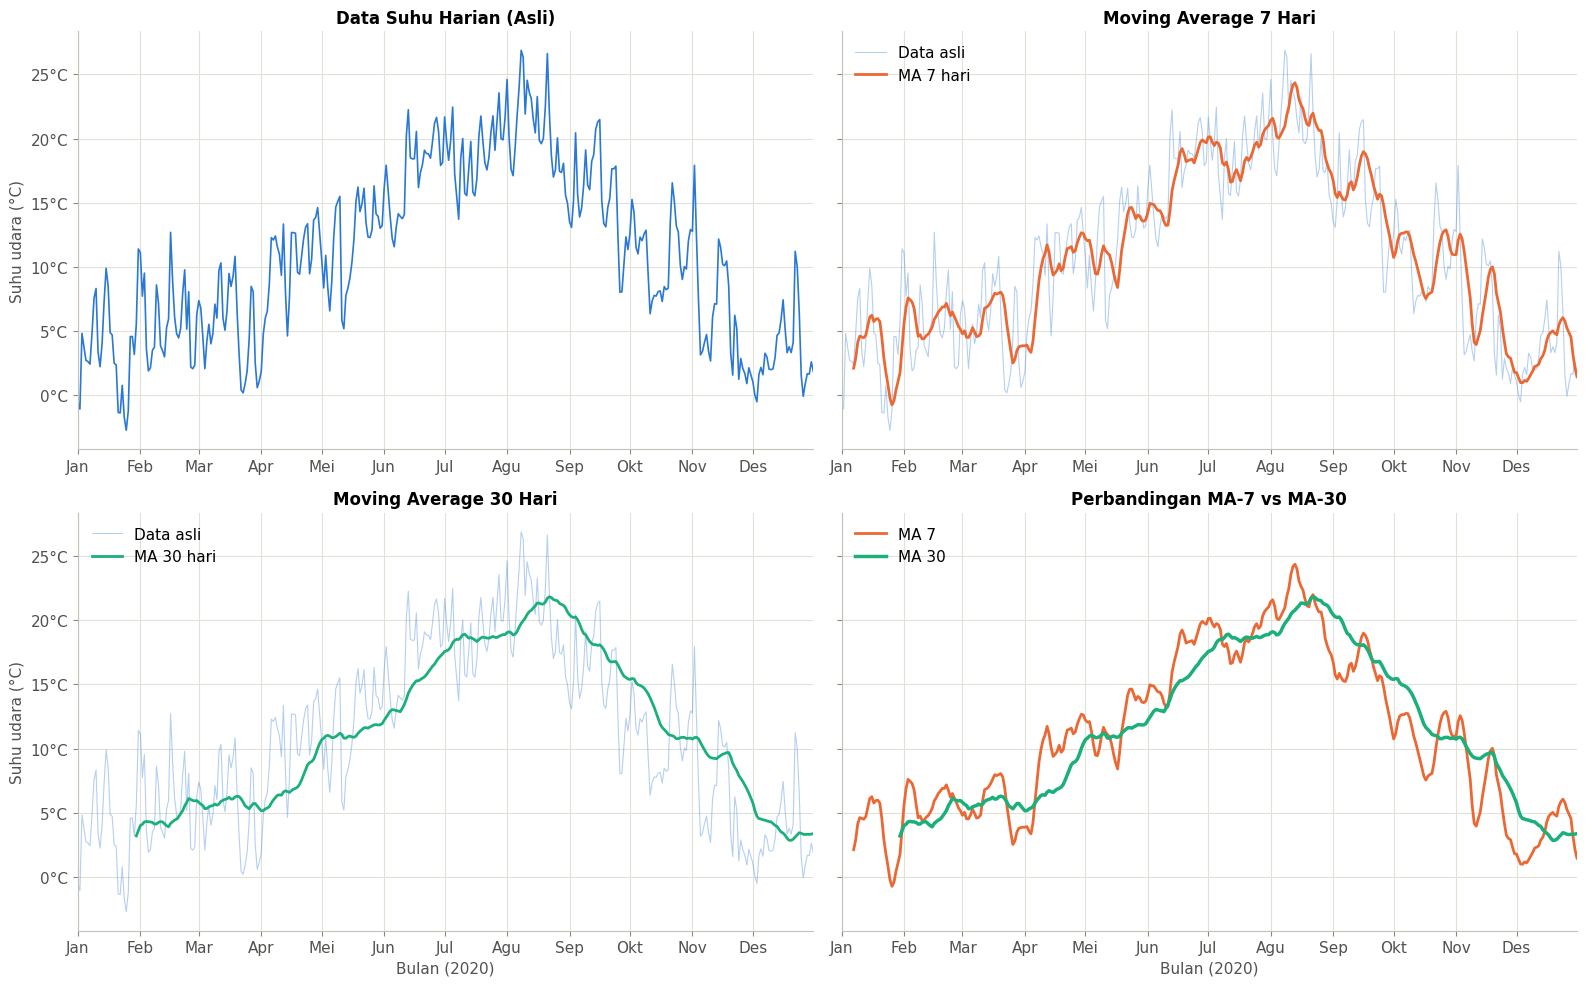

✓ 5_moving_average.png saved


In [ ]:
print('Generating 5_moving_average.png...')

daily_temp = suhu_harian[['T_mean']].rename(columns={'T_mean': 'T'})
daily_temp['MA_7'] = daily_temp['T'].rolling(window=7).mean()
daily_temp['MA_30'] = daily_temp['T'].rolling(window=30).mean()

print('=== Moving Average Information ===')
print(f'MA 7 hari : {daily_temp["MA_7"].isna().sum()} NaN values (data awal hilang)')
print(f'MA 30 hari: {daily_temp["MA_30"].isna().sum()} NaN values (data awal hilang)')
print(f'Total data points: {len(daily_temp)} hari')

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)

ax = axes[0, 0]
ax.plot(daily_temp.index, daily_temp['T'], linewidth=1.2, color=BIRU)
ax.set_title('Data Suhu Harian (Asli)', fontsize=12)

ax = axes[0, 1]
ax.plot(daily_temp.index, daily_temp['T'], linewidth=0.8, alpha=0.35, color=BIRU, label='Data asli')
ax.plot(daily_temp.index, daily_temp['MA_7'], linewidth=2, color=ORANYE, label='MA 7 hari')
ax.set_title('Moving Average 7 Hari', fontsize=12)
ax.legend(loc='upper left')

ax = axes[1, 0]
ax.plot(daily_temp.index, daily_temp['T'], linewidth=0.8, alpha=0.35, color=BIRU, label='Data asli')
ax.plot(daily_temp.index, daily_temp['MA_30'], linewidth=2, color=TOSKA, label='MA 30 hari')
ax.set_title('Moving Average 30 Hari', fontsize=12)
ax.legend(loc='upper left')

ax = axes[1, 1]
ax.plot(daily_temp.index, daily_temp['MA_7'], linewidth=2, color=ORANYE, label='MA 7')
ax.plot(daily_temp.index, daily_temp['MA_30'], linewidth=2.5, color=TOSKA, label='MA 30')
ax.set_title('Perbandingan MA-7 vs MA-30', fontsize=12)
ax.legend(loc='upper left')

for ax in axes.flat:
    format_sumbu_bulan(ax)
    format_celsius(ax)
    ax.set_xlim(daily_temp.index[0], daily_temp.index[-1])
for ax in axes[:, 0]:
    ax.set_ylabel('Suhu udara (°C)')
for ax in axes[1, :]:
    ax.set_xlabel(f'Bulan ({TAHUN})')

plt.tight_layout()
plt.savefig('5_moving_average.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ 5_moving_average.png saved')

### 3.2 Trade-off Analysis Moving Average

Angka di bawah dihitung langsung dari data:
- **Noise** = simpangan baku perubahan suhu dari hari ke hari. Makin kecil, makin halus kurvanya.
- **Lag** = berapa hari puncak kurva MA tertinggal dari puncak data asli. Ini terjadi karena MA memakai data *masa lalu* (trailing window).

In [ ]:
print('=== TRADE-OFF ANALISIS WINDOW SIZE ===')

noise_asli = daily_temp['T'].diff().std()
puncak_asli = daily_temp['T'].idxmax()
info = {}
for w in (7, 30):
    seri = daily_temp[f'MA_{w}']
    info[w] = {
        'nan': int(seri.isna().sum()),
        'noise': seri.diff().std(),
        'lag': (seri.idxmax() - puncak_asli).days,
    }
    info[w]['reduksi'] = (1 - info[w]['noise'] / noise_asli) * 100

print(f'\nData asli: noise {noise_asli:.2f} °C/hari, puncak pada {tgl_id(puncak_asli)}')

print('\n1. MA 7 hari:')
print(f'   ✓ Responsif terhadap perubahan jangka pendek (puncak hanya tertinggal {info[7]["lag"]} hari)')
print('   ✓ Detail fluktuasi mingguan (gelombang panas/dingin singkat) masih terlihat')
print(f'   ✗ Noise masih cukup terasa: {info[7]["noise"]:.2f} °C/hari (turun {info[7]["reduksi"]:.0f}%)')
print(f'   ✗ {info[7]["nan"]} data pertama hilang (NaN)')

print('\n2. MA 30 hari:')
print('   ✓ Kurva jauh lebih halus, siklus musiman tahunan terlihat jelas')
print(f'   ✓ Noise tereduksi kuat: {info[30]["noise"]:.2f} °C/hari (turun {info[30]["reduksi"]:.0f}%)')
print(f'   ✗ Puncak tertinggal {info[30]["lag"]} hari dari data asli (lag)')
print(f'   ✗ {info[30]["nan"]} data pertama hilang (NaN), hampir seluruh bulan Januari')

print('\n>>> KESIMPULAN:')
print('   Window lebih BESAR -> kurva HALUS, tapi DATA AWAL HILANG & respons TERLAMBAT (lag)')
print('   Window lebih KECIL -> lebih DETAIL & responsif, tapi NOISE tetap ADA')
print('   MA 30 hari lebih optimal untuk melihat tren musiman suhu;')
print('   MA 7 hari lebih cocok untuk memantau perubahan cuaca mingguan.')

=== TRADE-OFF ANALISIS WINDOW SIZE ===

Data asli: noise 2.43 °C/hari, puncak pada 8 Agu 2020

1. MA 7 hari:
   ✓ Responsif terhadap perubahan jangka pendek (puncak hanya tertinggal 5 hari)
   ✓ Detail fluktuasi mingguan (gelombang panas/dingin singkat) masih terlihat
   ✗ Noise masih cukup terasa: 0.64 °C/hari (turun 74%)
   ✗ 6 data pertama hilang (NaN)

2. MA 30 hari:
   ✓ Kurva jauh lebih halus, siklus musiman tahunan terlihat jelas
   ✓ Noise tereduksi kuat: 0.19 °C/hari (turun 92%)
   ✗ Puncak tertinggal 14 hari dari data asli (lag)
   ✗ 29 data pertama hilang (NaN), hampir seluruh bulan Januari

>>> KESIMPULAN:
   Window lebih BESAR -> kurva HALUS, tapi DATA AWAL HILANG & respons TERLAMBAT (lag)
   Window lebih KECIL -> lebih DETAIL & responsif, tapi NOISE tetap ADA
   MA 30 hari lebih optimal untuk melihat tren musiman suhu;
   MA 7 hari lebih cocok untuk memantau perubahan cuaca mingguan.


### 3.3 Curve Fitting - Linear & Polynomial Trend

Model dipasang ke suhu rata-rata harian dengan `x` = hari ke- (0 = 1 Januari 2020) dan `y` = suhu harian (°C).

Generating 6_curve_fitting.png...


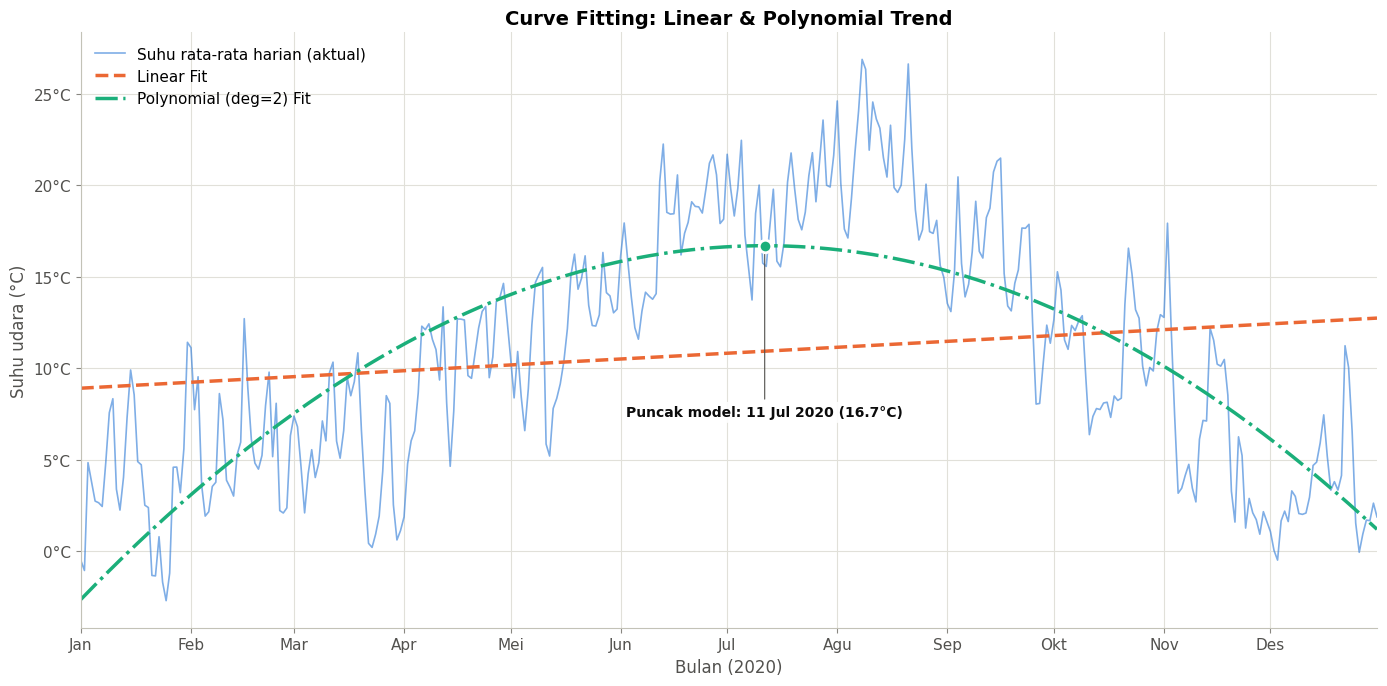

✓ 6_curve_fitting.png saved


In [ ]:
print('Generating 6_curve_fitting.png...')

data_fit = daily_temp['T'].dropna()
x = np.arange(len(data_fit))       # hari ke-0 ... ke-365
y = data_fit.values

z_linear = np.polyfit(x, y, 1)
p_linear = np.poly1d(z_linear)

z_poly2 = np.polyfit(x, y, 2)
p_poly2 = np.poly1d(z_poly2)

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(data_fit.index, y, linewidth=1.2, alpha=0.6, color=BIRU,
        label='Suhu rata-rata harian (aktual)')
ax.plot(data_fit.index, p_linear(x), linewidth=2.5, color=ORANYE,
        linestyle='--', label='Linear Fit')
ax.plot(data_fit.index, p_poly2(x), linewidth=2.5, color=TOSKA,
        linestyle='-.', label='Polynomial (deg=2) Fit')

# Tandai puncak parabola (titik balik model polinomial)
if z_poly2[0] < 0:
    x_puncak = -z_poly2[1] / (2 * z_poly2[0])
    tgl_puncak = data_fit.index[0] + pd.Timedelta(days=float(x_puncak))
    y_puncak = p_poly2(x_puncak)
    ax.plot(tgl_puncak, y_puncak, 'o', markersize=9, color=TOSKA,
            markeredgecolor='white', markeredgewidth=2, zorder=5)
    # Teks diletakkan di area kosong di bawah kurva, dihubungkan garis penunjuk
    ax.annotate(f'Puncak model: {tgl_id(tgl_puncak)} ({y_puncak:.1f}°C)',
                xy=(tgl_puncak, y_puncak), xytext=(0, -120), textcoords='offset points',
                ha='center', va='center', fontsize=10, fontweight='bold', color=TINTA,
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.9),
                arrowprops=dict(arrowstyle='-', color=TINTA_2, lw=0.8))

ax.set_xlabel(f'Bulan ({TAHUN})', fontsize=12)
ax.set_ylabel('Suhu udara (°C)', fontsize=12)
ax.set_title('Curve Fitting: Linear & Polynomial Trend', fontsize=14)
format_sumbu_bulan(ax)
format_celsius(ax)
ax.set_xlim(data_fit.index[0], data_fit.index[-1])
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('6_curve_fitting.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ 6_curve_fitting.png saved')

### 3.4 Trend Model Interpretation

In [ ]:
print('=== KOEFISIEN MODEL ===')
print(f'\nLinear            : y = {z_linear[0]:.4f}x + {z_linear[1]:.2f}')
print(f'Polynomial (deg=2): y = {z_poly2[0]:.6f}x² + {z_poly2[1]:.4f}x + {z_poly2[2]:.2f}')
print('(x = hari ke-, 0 = 1 Januari; y = suhu rata-rata harian dalam °C)')

print('\n=== INTERPRETASI TREN ===')
if z_linear[0] > 0:
    print('✓ Tren LINEAR POSITIF')
    print(f'  Suhu rata-rata NAIK {z_linear[0]:.4f} °C per hari (≈ {z_linear[0] * 30.44:.2f} °C per bulan)')
else:
    print('✗ Tren LINEAR NEGATIF')
    print(f'  Suhu rata-rata TURUN {abs(z_linear[0]):.4f} °C per hari (≈ {abs(z_linear[0]) * 30.44:.2f} °C per bulan)')

if z_poly2[0] < 0:
    print('\n✓ Polynomial: koefisien x² NEGATIF (parabola membuka ke bawah)')
    print('  Trend: naik di awal, kemudian turun (inverted U-shape)')
    print(f'  Puncak model pada hari ke-{x_puncak:.0f} = {tgl_id(tgl_puncak)} ({y_puncak:.1f} °C)')
else:
    print('\n✓ Polynomial: koefisien x² POSITIF (parabola membuka ke atas)')
    print('  Trend: turun di awal, kemudian naik (U-shape)')

ss_tot = np.sum((y - np.mean(y)) ** 2)
residuals_linear = y - p_linear(x)
r2_linear = 1 - np.sum(residuals_linear ** 2) / ss_tot
rmse_linear = np.sqrt(np.mean(residuals_linear ** 2))

residuals_poly2 = y - p_poly2(x)
r2_poly2 = 1 - np.sum(residuals_poly2 ** 2) / ss_tot
rmse_poly2 = np.sqrt(np.mean(residuals_poly2 ** 2))

print('\n=== MODEL FIT QUALITY ===')
print(f'R² Linear     : {r2_linear:.4f}   | RMSE: {rmse_linear:.2f} °C')
print(f'R² Polynomial : {r2_poly2:.4f}   | RMSE: {rmse_poly2:.2f} °C')

if r2_poly2 > r2_linear:
    print(f'\n>>> Polynomial fit lebih baik (R² {r2_poly2 - r2_linear:.4f} lebih tinggi)')
    print(f'    Polynomial menjelaskan {r2_poly2 * 100:.1f}% variasi suhu harian, '
          f'linear hanya {r2_linear * 100:.1f}%')
else:
    print('\n>>> Linear fit sudah cukup baik')

=== KOEFISIEN MODEL ===

Linear            : y = 0.0105x + 8.90
Polynomial (deg=2): y = -0.000521x² + 0.2007x + -2.64
(x = hari ke-, 0 = 1 Januari; y = suhu rata-rata harian dalam °C)

=== INTERPRETASI TREN ===
✓ Tren LINEAR POSITIF
  Suhu rata-rata NAIK 0.0105 °C per hari (≈ 0.32 °C per bulan)

✓ Polynomial: koefisien x² NEGATIF (parabola membuka ke bawah)
  Trend: naik di awal, kemudian turun (inverted U-shape)
  Puncak model pada hari ke-193 = 11 Jul 2020 (16.7 °C)

=== MODEL FIT QUALITY ===
R² Linear     : 0.0274   | RMSE: 6.61 °C
R² Polynomial : 0.6301   | RMSE: 4.08 °C

>>> Polynomial fit lebih baik (R² 0.6027 lebih tinggi)
    Polynomial menjelaskan 63.0% variasi suhu harian, linear hanya 2.7%


**Interpretasi:**
- **Model linear tidak cocok** untuk data suhu setahun (R² ±0,03, hanya menjelaskan ±3 % variasi). Kemiringannya memang positif (±0,01 °C/hari), tetapi itu **bukan tanda pemanasan**. Garis condong naik hanya karena bulan-bulan hangat (Jun–Sep) berada di paruh kedua tahun, sedangkan Jan–Mar dingin.
- **Polynomial derajat 2 jauh lebih baik** (R² ±0,63). Koefisien x² negatif membentuk lengkung terbalik: suhu naik dari awal tahun, memuncak sekitar **11 Juli (±16,7 °C)**, lalu turun. Puncak data aktual (8 Agustus) sedikit lebih lambat karena parabola selalu simetris, sedangkan pola suhu asli tidak simetris.
- **Catatan penting:** dengan data 1 tahun, lengkung ini adalah **siklus musiman**, bukan tren jangka panjang. Untuk mengukur tren sesungguhnya (misalnya kenaikan suhu antar tahun) dibutuhkan data beberapa tahun. Untuk pola yang berulang tiap tahun, model sinusoidal/Fourier lebih tepat daripada polinomial.

## 4. Verifikasi File PNG

In [ ]:
import zipfile

print('=== VERIFIKASI FILE VISUALISASI ===')
print('\nFile PNG yang telah di-generate:')

png_files = [
    '1_line_plot.png',
    '2_area_plot.png',
    '3_multiple_series.png',
    '4_seasonal_plot.png',
    '5_moving_average.png',
    '6_curve_fitting.png'
]

for i, filename in enumerate(png_files, 1):
    if os.path.exists(filename):
        file_size = os.path.getsize(filename) / 1024
        print(f'  ✓ {i}. {filename} ({file_size:.1f} KB)')
    else:
        print(f'  ✗ {i}. {filename} (NOT FOUND)')

# Kumpulkan semua PNG dalam 1 file zip (memudahkan unduh dari Colab)
ZIP_NAME = 'hasil_visualisasi_cuaca.zip'
with zipfile.ZipFile(ZIP_NAME, 'w') as zf:
    for filename in png_files:
        if os.path.exists(filename):
            zf.write(filename)
print(f'\nSemua PNG juga dikemas ke: {ZIP_NAME}')

UNDUH_ZIP = False   # ubah ke True jika di Colab ingin langsung mengunduh zip
if IN_COLAB and UNDUH_ZIP:
    from google.colab import files
    files.download(ZIP_NAME)
elif IN_COLAB:
    print('Di Colab: unduh dari panel Files (ikon folder di kiri) atau set UNDUH_ZIP = True.')

print('\n=== READY FOR REPORT ===')
print('Semua file PNG dapat dimasukkan ke dalam laporan Word.')

=== VERIFIKASI FILE VISUALISASI ===

File PNG yang telah di-generate:
  ✓ 1. 1_line_plot.png (613.6 KB)
  ✓ 2. 2_area_plot.png (638.0 KB)
  ✓ 3. 3_multiple_series.png (377.1 KB)
  ✓ 4. 4_seasonal_plot.png (361.6 KB)
  ✓ 5. 5_moving_average.png (1071.2 KB)
  ✓ 6. 6_curve_fitting.png (532.9 KB)

Semua PNG juga dikemas ke: hasil_visualisasi_cuaca.zip
Di Colab: unduh dari panel Files (ikon folder di kiri) atau set UNDUH_ZIP = True.

=== READY FOR REPORT ===
Semua file PNG dapat dimasukkan ke dalam laporan Word.


## 5. Ringkasan Temuan

| Aspek | Temuan utama |
|---|---|
| Kualitas data | 1 timestamp duplikat, 1 baris di luar 2020, 31 kode error `-9999` (`wv` & `max. PAR`), 1 celah 1 jam 40 menit (29 Mei 2020) |
| Tren suhu (2.1) | Siklus musiman: terdingin 25 Jan (−2,7 °C), terpanas 8 Agu (26,9 °C), rata-rata tahunan 10,8 °C |
| Curah hujan (2.2) | Total 620,4 mm; terbasah Agustus, terkering November; hujan paling banyak turun siang hari (33,5 %) |
| Variabel suhu (2.3) | T, Tdew, Tlog bergerak searah; udara paling kering di April, paling lembap di Desember |
| Pola harian (2.4) | Suhu minimum 04:00–06:00, maksimum 14:00–15:00; amplitudo terbesar di musim semi |
| Moving average (3.1–3.2) | MA-30 menurunkan noise ±92 % tapi tertinggal ±14 hari; MA-7 lebih responsif |
| Curve fitting (3.3–3.4) | Polynomial (R² ±0,63) jauh lebih baik dari linear (R² ±0,03); pola = siklus musiman |